# 08-PD控制


## 1. 本课目标：给 T800 上发条

本篇对应《具身智能机器人实战》第 08 节《PD 控制》，副标题为“给 T800 上发条”。上一节通过主循环推进物理仿真，本节开始根据关节的当前位置和速度，计算推动它接近目标的控制输入。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/08_PD控制.pptx` 全部 4 页：第 2 页对比直接改角度与电机驱动，第 3 页解释比例项和微分项，第 4 页为品牌结束页。

课件没有给出公式、增益数值或代码。第 4、5 节将公式与 MuJoCo 示例标为“工程补充”。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. 目标角度怎样变成关节运动

课件先用机械臂对比两种做法：

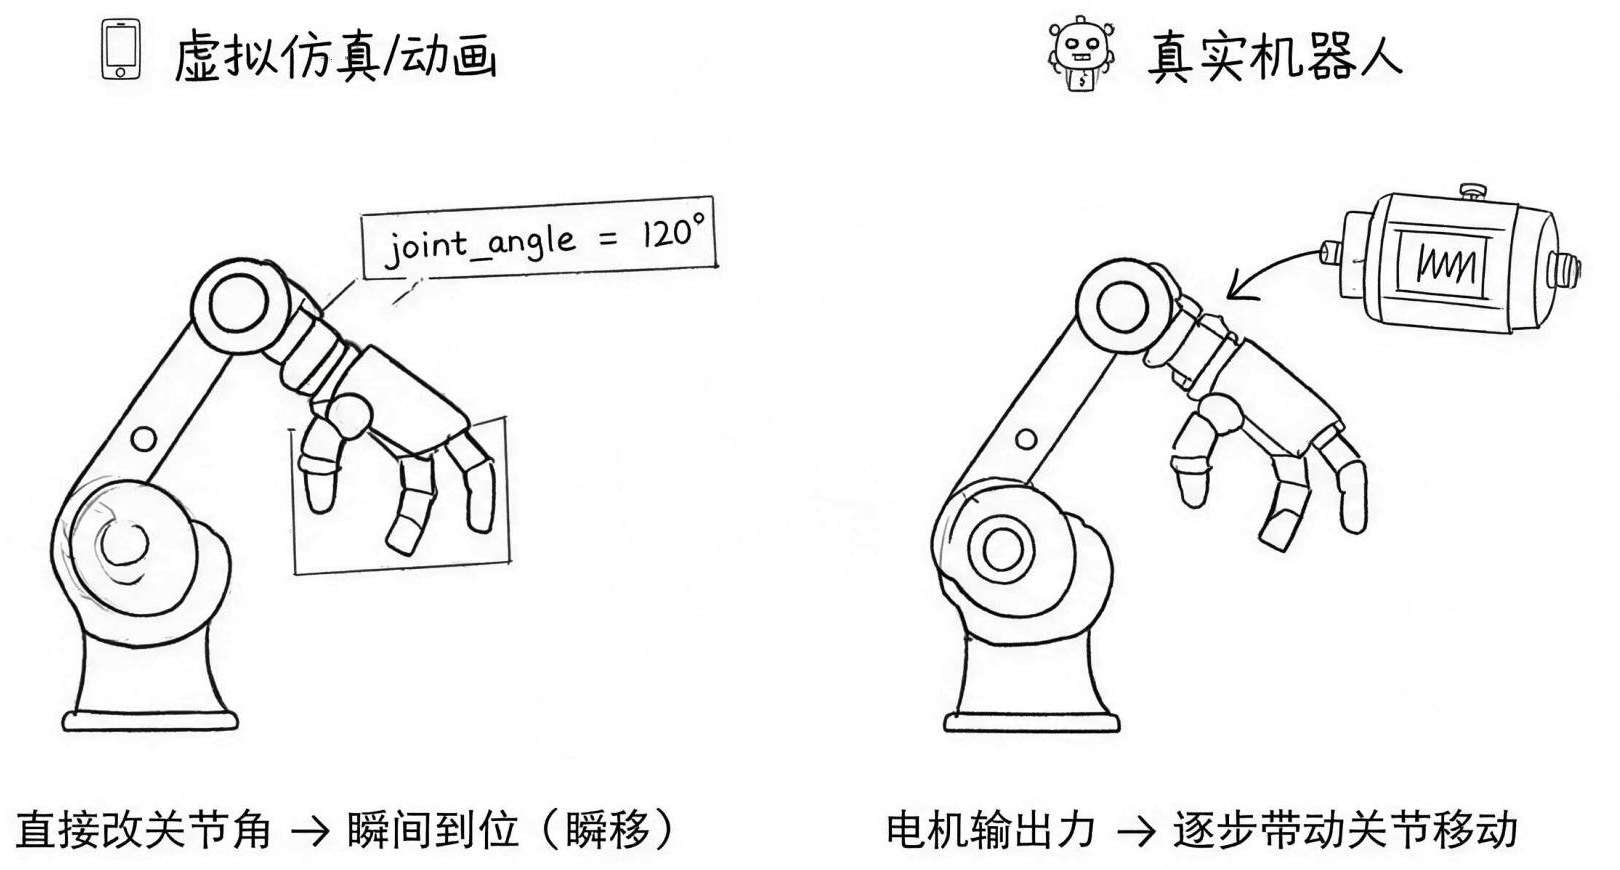

*原课件第 2 页：左侧直接修改 `joint_angle = 120°`，右侧由电机输出作用力，逐步带动关节移动。*

左图表示直接改变姿态数据，关节可以立即出现在指定角度。右图表示通过驱动作用让关节经历运动过程，当前位置、速度以及受力共同影响它接下来怎样变化。

对于转动关节，驱动作用通常用力矩描述。控制器需要把“希望到达哪里”转换成“本步应该输出多大的力矩”，再让物理引擎计算运动。

**工程补充：**MuJoCo 也可以仿真受力运动，课件左侧强调的是直接改状态这种操作方式。修改 `data.qpos` 适合设置初始姿态或重置状态；在主循环中驱动 motor，应根据反馈计算输入并写入对应的 `data.ctrl`。真实伺服系统也可以提供目标角度接口，其内部仍需控制器和电机来实现运动。

图中的 `120°` 只是示意，没有指定某个 T800 关节。不能把它当成所有关节通用的测试目标。


## 3. P 是弹簧，D 是刹车垫

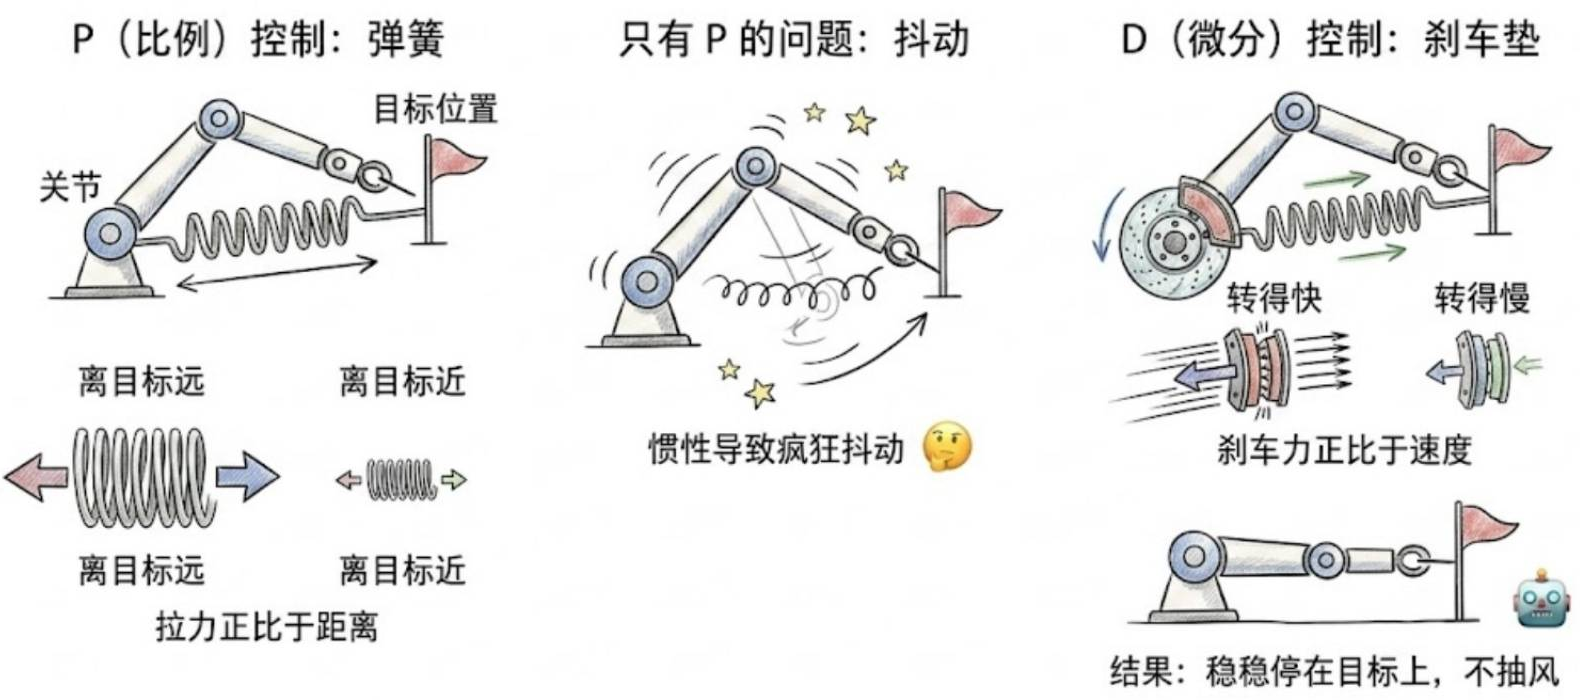

*原课件第 3 页：依次展示 P 项的拉力、只有 P 时的抖动，以及 D 项对速度的抑制作用。*

### 3.1 P：按位置误差拉向目标

P 是比例控制。课件把它类比为连接关节与目标的弹簧：离目标远时拉力大，离目标近时拉力小，拉力大小正比于距离。

对应关节控制，这里的“距离”是目标角度与当前角度之间的误差。比例增益决定同样大小的误差产生多强的驱动作用。

### 3.2 只有 P 时，可能越过目标后反复摆动

关节运动具有惯性。即使到达目标时位置误差已经变小，速度也未必降为零。关节可能继续越过目标，随后被反向拉回，形成振荡。

课件用抖动的机械臂表示这种现象，说明仅根据位置误差决定驱动力，还缺少对运动速度的约束。

### 3.3 D：按速度提供阻尼

D 是微分控制。课件把它类比为刹车垫：转得快时制动作用大，转得慢时制动作用小，制动大小正比于速度。

对于保持不变的目标角度，D 项提供与当前速度方向相反的力矩，帮助关节在接近目标时减速。P 项负责拉向目标，D 项帮助减少反复摆动，两者共同构成 PD 控制。

**工程补充：**图中的“只有 P 就抖动”和“加 D 后稳稳停住”是定性类比。实际表现还取决于增益、惯性、已有阻尼、采样步长和负载。加入 D 并不自动保证稳定或无误差停在目标，纯 PD 在重力等持续负载下也可能存在稳态位置误差。


## 4. 工程补充：把弹簧与阻尼写成公式

对于单轴转动关节，令当前位置为 $q$，当前角速度为 $\dot q$，目标位置与目标速度分别为 $q_{\mathrm{target}}$、$\dot q_{\mathrm{target}}$，一种常见的 PD 力矩公式是：

$$
\tau = K_p(q_{\mathrm{target}}-q)
       + K_d(\dot q_{\mathrm{target}}-\dot q)
$$

| 符号 | 含义 |
|---|---|
| $K_p$ | 比例增益，决定位置误差产生的力矩 |
| $K_d$ | 微分增益，决定速度误差产生的力矩 |
| $\tau$ | 计算得到的关节力矩指令 |

保持固定目标时，目标速度为零，公式简化为：

$$
\tau = K_p(q_{\mathrm{target}}-q)-K_d\dot q
$$

对弧度制转动关节，$K_p$ 的单位可写作 N·m/rad，$K_d$ 的单位可写作 N·m·s/rad。

正负号很关键：在 $K_p、K_d$ 为正的情况下，当前位置小于目标且静止时，P 项给出正力矩；关节正向转动时，D 项给出负力矩，抑制这一方向的速度。即使位置已经到达目标，只要关节仍在运动，D 项仍可能非零。

每一步都要重新读取位置和速度，再计算本步力矩。只在循环开始时算一次，就无法持续根据反馈修正输入。


## 5. 工程补充：在 T800 主循环中计算 PD 输入

沿用第 03～07 篇的 `t800-load` 练习目录、官方模型与 `.venv`，新建 `pd_t800.py`。本例使用已核对的官方模型提交 `335c60e88772c26c7852d0abd6b3c7439037dd8f`，只演示右肩俯仰关节的短时控制数据通路。

该版本的 `motor_J18_SHOULDER_PITCH_R` 连接单轴转动关节 `J18_SHOULDER_PITCH_R`，并设置 `gear="1"`，所以这里可将计算的力矩作为该 motor 的控制输入。其他执行器需按自身配置解释 `ctrl`。

示例选用目标 `0.1 rad`、`Kp=20`、`Kd=2`，运行 100 步。这些是本篇用于演示的数值，课件没有提供这组参数，也未将它们作为整机站立或实机控制参数。其余执行器输入保持为零。

```python
import argparse
from pathlib import Path

import mujoco


def pd_torque(q, dq, target, kp, kd):
    return kp * (target - q) - kd * dq


parser = argparse.ArgumentParser(description="T800 单关节 PD 输入示例")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
args = parser.parse_args()
model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

joint_id = model.joint("J18_SHOULDER_PITCH_R").id
qpos_index = int(model.jnt_qposadr[joint_id])
qvel_index = int(model.jnt_dofadr[joint_id])
actuator_id = model.actuator("motor_J18_SHOULDER_PITCH_R").id
target = 0.1
kp, kd = 20.0, 2.0

for _ in range(100):
    q = float(data.qpos[qpos_index])
    dq = float(data.qvel[qvel_index])
    data.ctrl[:] = 0.0
    data.ctrl[actuator_id] = pd_torque(q, dq, target, kp, kd)
    mujoco.mj_step(model, data)

print(f"time={data.time:.3f}")
print(f"target={target:.6f}, q={data.qpos[qpos_index]:.6f}")
print(f"dq={data.qvel[qvel_index]:.6f}")
```

这里分别查询位置数组地址、速度数组地址和执行器 ID，延续第 06 篇的下标规则。每一轮先读取状态、计算 PD 输入，再调用 `mj_step()`，没有在循环中直接改写 `qpos`。

在 `t800-load` 目录的 PowerShell 中执行：

```powershell
.\.venv\Scripts\python.exe pd_t800.py
```

模型位于其他目录时，可增加 `--model` 指定保留完整资源目录的场景入口。本篇在 MuJoCo 3.4.0 与上述官方模型上实际运行，输出为：

```text
time=0.200
target=0.100000, q=0.103705
dq=0.607481
```

初始关节角与速度均为零，第一次输入为 `20 × (0.1 - 0) - 2 × 0 = 2 N·m`。随后输入随状态变化重新计算。本次运行中输入处于模型已有的控制范围内，力矩范围的进一步处理放在下一节学习。

0.2 秒时关节位置接近目标，但角速度仍为 `0.607481 rad/s`，说明它尚未静止。该结果只验证 PD 输入确实参与了物理步进，不能据此认定已经稳定收敛或整机能够站立。本次没有打开图形查看器。


## 6. 本课检查与补充参考

完成本节，应能解释直接设置姿态与施加力矩的区别，用弹簧和阻尼说明 P、D 两项，并在主循环中根据当前位置、速度重新计算控制输入。

补充示例已在官方 T800 模型上运行 100 步，核对公式方向、关节与执行器映射、时间推进及状态数值有限。没有验证整机稳定性或真实硬件。

- [本篇版本的 T800 关节定义](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_links.xml)。
- [同版本的 motor 配置](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_actuators.xml)。
- [MuJoCo 3.4.0：motor 执行器](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#actuator-motor)。
- [MuJoCo 3.4.0：gear 与传动缩放](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#actuator-general-gear)。
